In [1]:
import os
import pandas as pd
import numpy as np
import pingouin as pg

In [2]:
Dir_github = r'X:\PROJECTS\ABC@UofSC\3-Experiments\NSF_valence\github\nsf_valence'
Dir_ratings = os.path.join(Dir_github,'derivatives','behavioral','ratings','text')
df_ratings_text = pd.read_csv(os.path.join(Dir_ratings,'ratings_text_att2_comp2.csv'), dtype={'idx': str,'ethnicity':str},keep_default_na=False)
Dir_ratings = os.path.join(Dir_github,'derivatives','behavioral','ratings','audio')
df_ratings_audio = pd.read_csv(os.path.join(Dir_ratings,'ratings_audio_att2_comp2.csv'), dtype={'idx': str,'ethnicity':str},keep_default_na=False)
df_ratings_audio['modality'] = 'audio'
df_ratings_text['modality'] = 'text'
df_ratings = pd.concat([df_ratings_audio,df_ratings_text],ignore_index=True)
df_ratings

,group,subID,idx,audio,audio_idx,segID,V,A,RT,age,...,attention_correct,attention_correct%,comp_correct,comp_correct%,source,ethnicity,residence_states,modality,text,text_idx
0,young,young_49058,49058,Jacob_BradfordBoar,1.0,1,0.07500,3.41250,3.617,20.0,...,3.0,1.0,3.0,0.6,Sona,Black,South Carolina (SC),audio,NaN,NaN
1,young,young_49058,49058,Jacob_BradfordBoar,1.0,2,0.05625,4.51875,1.725,20.0,...,3.0,1.0,3.0,0.6,Sona,Black,South Carolina (SC),audio,NaN,NaN
2,young,young_49058,49058,Jacob_BradfordBoar,1.0,3,1.95000,6.58125,3.862,20.0,...,3.0,1.0,3.0,0.6,Sona,Black,South Carolina (SC),audio,NaN,NaN
3,young,young_49058,49058,Jacob_BradfordBoar,1.0,4,0.05625,4.06875,1.692,20.0,...,3.0,1.0,3.0,0.6,Sona,Black,South Carolina (SC),audio,NaN,NaN
4,young,young_49058,49058,Jacob_BradfordBoar,1.0,5,0.03750,5.06250,2.633,20.0,...,3.0,1.0,3.0,0.6,Sona,Black,South Carolina (SC),audio,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
434899,old,old_680d155019b77b986ff85126,680d155019b77b986ff85126,NaN,NaN,117,2.85000,6.50625,3.621,65.0,...,3.0,1.0,4.0,1.0,Prolific,White,North Carolina (NC),text,FirstConcert,2.0
434900,old,old_680d155019b77b986ff85126,680d155019b77b986ff85126,NaN,NaN,118,1.96875,7.31250,1.502,65.0,...,3.0,1.0,4.0,1.0,Prolific,White,North Carolina (NC),text,FirstConcert,2.0
434901,old,old_680d155019b77b986ff85126,680d155019b77b986ff85126,NaN,NaN,119,-3.80625,8.43750,3.901,65.0,...,3.0,1.0,4.0,1.0,Prolific,White,North Carolina (NC),text,FirstConcert,2.0
434902,old,old_680d155019b77b986ff85126,680d155019b77b986ff85126,NaN,NaN,120,-3.13125,7.44375,4.229,65.0,...,3.0,1.0,4.0,1.0,Prolific,White,North Carolina (NC),text,FirstConcert,2.0


In [24]:
df_ratings_audio_mean = df_ratings_audio.groupby(['group','audio','segID']).mean(numeric_only=True)[['V','A']].reset_index()

In [ ]:
df_ratings_audio_mean

,group,audio,segID,V,A
0,middle,Allison_AgedMother,1,0.690234,4.096875
1,middle,Allison_AgedMother,2,0.732422,4.671094
2,middle,Allison_AgedMother,3,-0.626953,4.687500
3,middle,Allison_AgedMother,4,1.219922,4.989844
4,middle,Allison_AgedMother,5,1.647656,4.800000
...,...,...,...,...,...
18061,young,WavenetF_Koko,90,1.280357,4.808036
18062,young,WavenetF_Koko,91,-0.012500,4.048214
18063,young,WavenetF_Koko,92,1.080357,5.506250
18064,young,WavenetF_Koko,93,0.200893,4.083929


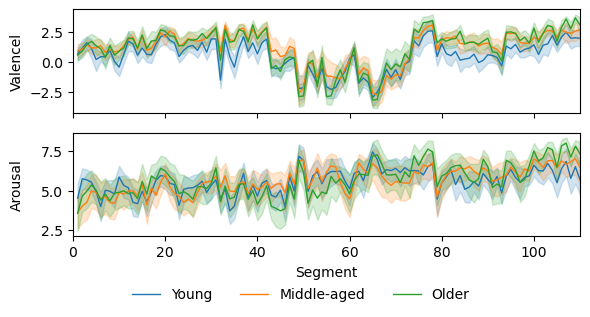

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

fig,axes = plt.subplots(nrows=2,ncols=1,figsize=(6,3),sharex=True)
audio = 'Brandi_FairyTree'
modalitiy = 'audio'
for ax,var,label in zip(axes.flatten(),['V','A'],['Valencel','Arousal']):
    df_plot = df_ratings.loc[(df_ratings['modality']==modalitiy)&(df_ratings['audio']==audio)]
    # df_plot = df_ratings_audio_mean.loc[df_ratings_audio_mean['audio']==audio]
    sns.lineplot(df_plot,x='segID',y=var,hue='group',
                #  errorbar='se',
                linewidth=1,ax=ax
                )
    ax.get_legend().set_visible(False)

    ax.set(ylabel = label,xlabel='Segment',xlim=[0,df_plot['segID'].max()])
plt.tight_layout()
fig.align_ylabels(axes)

# ax.set_xticks([0, 1])
# ax.set_xticklabels(['Listening', 'Reading'])

handles, labels = ax.get_legend_handles_labels()
new_labels_list = ['Young','Middle-aged','Older']

fig.legend(handles, new_labels_list, title='',ncol=3,
        frameon=False, loc='center', bbox_to_anchor=(0.51, 0))


Dir_output = os.path.join(Dir_github,'derivatives','behavioral','figures&tables') 
# fig.savefig(os.path.join(Dir_output,f"Fig1_linegraph.jpg"),dpi=600,bbox_inches='tight')

In [44]:
df_ratings['subID'].unique().shape

(723,)